# Cycle 4 - Optimisation des hyperparamètres de la Random Forest

In [63]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [64]:
import pandas as pd
from sklearn.pipeline import Pipeline
from agritech_feature_engineering import AgritechFeatureEngineering
from sklearn.model_selection import cross_validate, TimeSeriesSplit, RandomizedSearchCV
import mlflow
import notebooks.utils as utils
from datetime import datetime as dt
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [65]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")

In [66]:
dataset = pd.read_csv('../data/rafined/dataset.csv', sep=',')

In [67]:
dataset.drop(columns=['Area ISO Code', 'Area ISO Alpha-2 Code', 'Area ISO Alpha-3 Code'], inplace=True)

In [68]:
X_train, X_test, y_train, y_test = utils.test_train_time_split(dataset)

Année de césure calculée : 2009
Proportion réelle train : 78.73% (20349 lignes)
Proportion réelle test  : 21.27% (5499 lignes)


In [69]:
X_train = X_train.sort_values('Year')
y_train = y_train.loc[X_train.index]

In [70]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

numeric_features = [
    'avg_temp',
    'average_rain_fall_mm_per_year',
    'pesticides_tonnes',
    'pesticides_kg_ha',
    'aridity',
    'avg_temp_square',
    'missing_pesticide_value',
    'missing_rain_value',
    'missing_temp_value'
]

numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('area_encoding', TargetEncoder(target_type='continuous', random_state=42), ['Area']),
        ('item_encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Item']),
        ('num_pipeline', numeric_transformer, numeric_features),
    ],
    remainder='drop'
)

In [71]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)

In [72]:
pipeline = Pipeline([
    ('features', AgritechFeatureEngineering()),
    ('preprocessor', preprocessor),
    ('model', model)
])

In [73]:
# test de log le rendement car la distribution est très étalé
model_log = TransformedTargetRegressor(
    regressor=pipeline,
    func=np.log1p,
    inverse_func=np.expm1,
)

In [74]:
mlflow.set_experiment("Agriculture_optimization")
mlflow.end_run()
mlflow.set_system_metrics_sampling_interval(1)

In [75]:
scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

common_params = {
    'split': 'temporel',
    'split_year': int(X_test['Year'].min()),
    'model': 'RandomForestRegressor',
    'cv': 'TimeSeriesSplit 5 plis',
    'target_transform': 'log1p',
    'features': 'Area, Item, avg_temp, rain, pesticides, aridity, avg_temp_square, missing_*',
}

with mlflow.start_run(run_name="Cycle 4 - Random Forest par défaut (référence)", log_system_metrics=True):

    mlflow.set_tags({
        'date': dt.now().strftime("%Y-%m-%d"),
        'cycle': '4_optimisation',
        'model_type': 'random_forest',
        'mlflow.note.content': (
            "Random Forest avec ses paramètres par défaut et cible log1p : "
            "point de référence avant l'optimisation des hyperparamètres."
        ),
    })

    mlflow.log_params(common_params)
    mlflow.log_params({f'model__{k}': v for k, v in model.get_params().items()})

    cv_results = cross_validate(
        model_log,
        X_train,
        y_train,
        cv=TimeSeriesSplit(5),
        scoring=scoring,
        return_train_score=True,
        error_score='raise',
        n_jobs=-1,
    )

    default_metrics = {
        'r2': cv_results['test_r2'].mean(),
        'mae': -cv_results['test_mae'].mean(),
        'rmse': -cv_results['test_rmse'].mean(),
        'train_r2': cv_results['train_r2'].mean(),
        'train_mae': -cv_results['train_mae'].mean(),
        'train_rmse': -cv_results['train_rmse'].mean(),
        'fit_time_mean': cv_results['fit_time'].mean(),
    }
    default_metrics['r2_gap_train_val'] = default_metrics['train_r2'] - default_metrics['r2']
    mlflow.log_metrics(default_metrics)

    print('--- Validation Fold Results ---')
    print(f"Validation R2 : {cv_results['test_r2']}, R2 moyen : {cv_results['test_r2'].mean()}")
    print(f"Validation MAE : {cv_results['test_mae']}, MAE moyen : {cv_results['test_mae'].mean()}")
    print(f"Validation RMSE : {cv_results['test_rmse']}, RMSE moyen : {cv_results['test_rmse'].mean()}")

    print('--- Train Fold Results ---')
    print(f"Train R2 moyen : {cv_results['train_r2'].mean()}")
    print(f"Train MAE moyen : {-cv_results['train_mae'].mean()}")
    print(f"Train RMSE moyen : {-cv_results['train_rmse'].mean()}")

2026/11/11 11:16:31 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 11:16:31 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
/Users/auncly/Documents/Formation data scientist/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/auncly/Documents/Formation data scientist/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEnco

--- Validation Fold Results ---
Validation R2 : [0.86861228 0.86967942 0.83847188 0.89854003 0.89452663], R2 moyen : 0.8739660478768373
Validation MAE : [-13463.8120991  -13049.98668533 -14314.4115165  -12806.7756202
 -13249.31088878], MAE moyen : -13376.859361981053
Validation RMSE : [-25028.14565081 -25056.6785543  -29978.19758424 -23998.49691205
 -25100.64421336], RMSE moyen : -25832.43258295216
--- Train Fold Results ---
Train R2 moyen : 0.9656604489404778
Train MAE moyen : 5613.2262181147835
Train RMSE moyen : 12517.934618310459
🏃 View run Cycle 4 - Random Forest par défaut (référence) at: http://127.0.0.1:5000/#/experiments/1/runs/45571a3bcc034e9e9d5b0ac0c8eefdb7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [76]:
params = {
    # Nombre d'arbres dans la forêt
    'regressor__model__n_estimators': [100, 200, 500, 1000],
    # Nombre maximum de features à considérer pour splitter un nœud
    'regressor__model__max_features': ['sqrt', 'log2', 0.5, 1.0],
    # Profondeur maximale de chaque arbre (None = développement complet jusqu'aux feuilles pures)
    'regressor__model__max_depth': [10, 20, 30, 40, 50, None],
    # Nombre minimum d'échantillons requis pour diviser un nœud interne
    'regressor__model__min_samples_split': [2, 5, 10, 20],
    # Nombre minimum d'échantillons requis pour être dans une feuille terminale
    'regressor__model__min_samples_leaf': [1, 2, 4, 10],
    # Méthode d'échantillonnage des lignes (bootstrap avec ou sans remise)
    'regressor__model__bootstrap': [True, False],
}

n_iter = 20
prefix = 'regressor__model__'

search = RandomizedSearchCV(
    estimator=model_log,
    param_distributions=params,
    n_iter=n_iter,
    scoring=scoring,
    refit='rmse',
    cv=TimeSeriesSplit(5),
    return_train_score=True,
    random_state=42,
    n_jobs=-1,
)

with mlflow.start_run(run_name="Cycle 4 - Optimisation Random Forest (RandomizedSearchCV)", log_system_metrics=True) as opt_run:

    mlflow.set_tags({
        'date': dt.now().strftime("%Y-%m-%d"),
        'cycle': '4_optimisation',
        'model_type': 'random_forest',
        'mlflow.note.content': (
            f"Optimisation des hyperparamètres de la Random Forest par RandomizedSearchCV : "
            f"{n_iter} combinaisons tirées au hasard, évaluées en validation croisée temporelle (5 plis), "
            "meilleure combinaison choisie sur la RMSE."
        ),
    })

    mlflow.log_params({
        **common_params,
        'search': 'RandomizedSearchCV',
        'n_iter': n_iter,
        'refit_metric': 'rmse',
        'search_random_state': 42,
    })

    search.fit(X_train, y_train)

    # combinaison gagnante
    res = search.cv_results_
    i = search.best_index_
    best_params = {k.replace(prefix, 'model__'): v for k, v in search.best_params_.items()}
    best_metrics = {
        'r2': res['mean_test_r2'][i],
        'mae': -res['mean_test_mae'][i],
        'rmse': -res['mean_test_rmse'][i],
        'train_r2': res['mean_train_r2'][i],
        'train_mae': -res['mean_train_mae'][i],
        'train_rmse': -res['mean_train_rmse'][i],
    }
    best_metrics['r2_gap_train_val'] = best_metrics['train_r2'] - best_metrics['r2']
    gain_rmse_pct = (best_metrics['rmse'] / default_metrics['rmse'] - 1) * 100

    mlflow.log_params(best_params)
    mlflow.log_metrics({**best_metrics, 'gain_rmse_vs_default_pct': gain_rmse_pct})

print(f"Meilleurs paramètres : {best_params}")
print(f"RMSE moyenne en validation croisée : {best_metrics['rmse']:.0f} hg/ha (par défaut : {default_metrics['rmse']:.0f}, soit {gain_rmse_pct:+.1f} %)")
print(f"R2 validation : {best_metrics['r2']:.4f} | R2 train : {best_metrics['train_r2']:.4f} | écart : {best_metrics['r2_gap_train_val']:.4f}\n")

best_pipeline = search.best_estimator_
opt_run_id = opt_run.info.run_id

2026/11/11 11:16:39 INFO mlflow.system_metrics.system_metrics_monitor: Skip logging GPU metrics. Set logger level to DEBUG for more details.
2026/11/11 11:16:39 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
/Users/auncly/Documents/Formation data scientist/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/Users/auncly/Documents/Formation data scientist/12 - Concevez un système de recommandations pour une agriculture optimisée par les données/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEnco

🏃 View run Cycle 4 - Optimisation Random Forest (RandomizedSearchCV) at: http://127.0.0.1:5000/#/experiments/1/runs/46a3cfdeb228438f9b7119a93a99e098
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Meilleurs paramètres : {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 40, 'model__bootstrap': False}
RMSE moyenne en validation croisée : 24978 hg/ha (par défaut : 25832, soit -3.3 %)
R2 validation : 0.8821 | R2 train : 0.9822 | écart : 0.1001



🏃 View run Cycle 4 - Optimisation Random Forest (RandomizedSearchCV) at: http://127.0.0.1:5000/#/experiments/1/runs/46a3cfdeb228438f9b7119a93a99e098
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


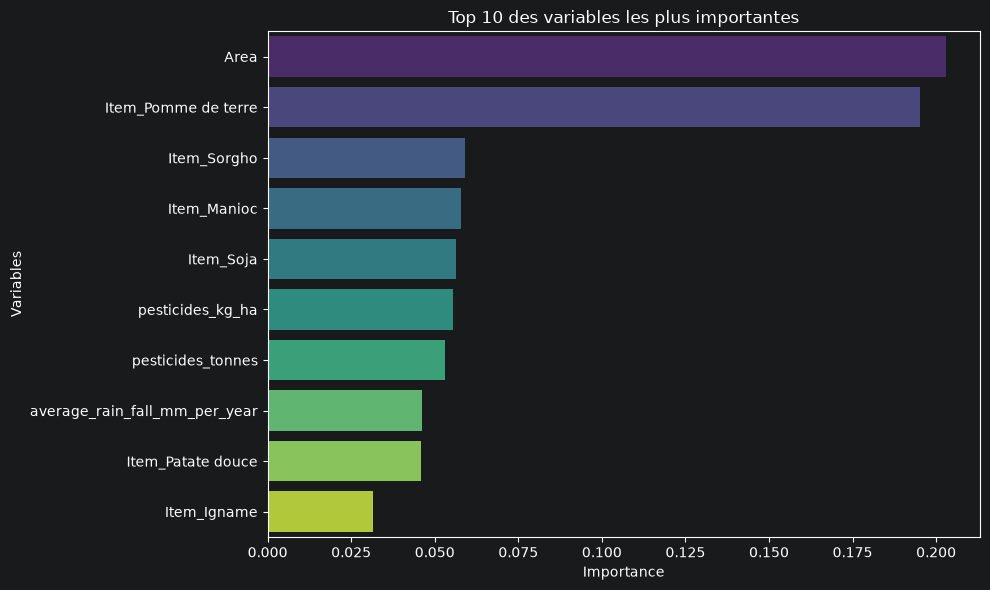

In [77]:
fitted_pipeline = search.best_estimator_.regressor_
rf = fitted_pipeline.named_steps['model']
noms_variables = fitted_pipeline.named_steps['preprocessor'].get_feature_names_out()

df_importance = pd.DataFrame({
  'Variable': noms_variables,
  'Importance': rf.feature_importances_
})

df_importance['Variable'] = df_importance['Variable'].str.split('__').str[1]

df_importance = df_importance.sort_values(by='Importance', ascending=False)

top_10 = df_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance',
    y='Variable',
    data=top_10,
    hue='Variable',
    palette='viridis',
    legend=False
)
plt.title("Top 10 des variables les plus importantes")
plt.xlabel("Importance")
plt.ylabel("Variables")
plt.tight_layout()
fig = plt.gcf()

# graphique rattaché au run d'optimisation dans MLflow
with mlflow.start_run(run_id=opt_run_id):
    mlflow.log_figure(fig, "top_10_variables.png")

plt.show()

🏃 View run Cycle 4 - Optimisation Random Forest (RandomizedSearchCV) at: http://127.0.0.1:5000/#/experiments/1/runs/46a3cfdeb228438f9b7119a93a99e098
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


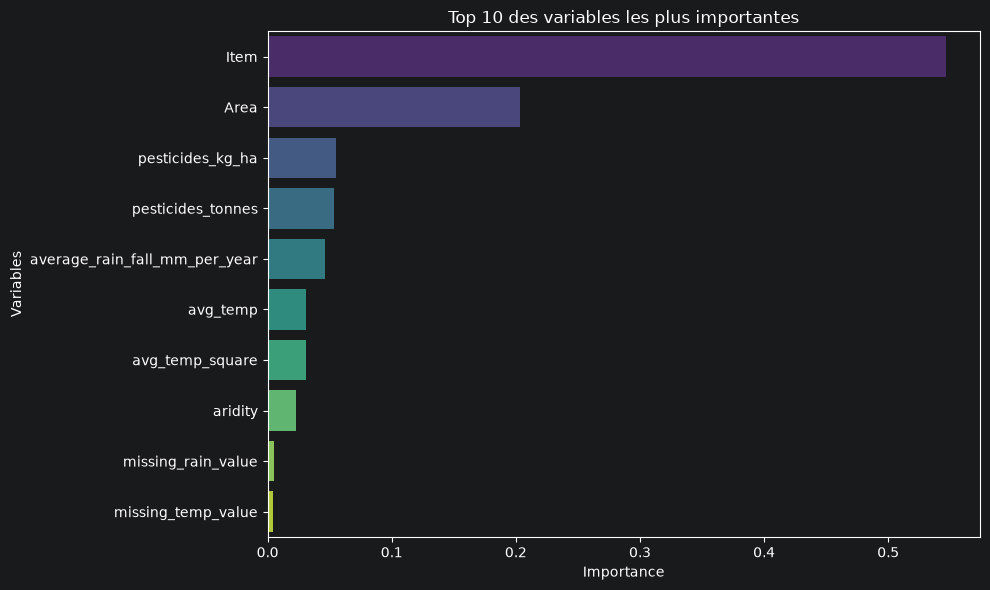

In [78]:
fitted_pipeline = search.best_estimator_.regressor_
rf = fitted_pipeline.named_steps['model']
noms_variables = fitted_pipeline.named_steps['preprocessor'].get_feature_names_out()

df_importance = pd.DataFrame({
  'Variable': noms_variables,
  'Importance': rf.feature_importances_
})

df_importance['Variable'] = df_importance['Variable'].str.split('__').str[1]

# regroupement des colonnes par culture en une variable "Item"
df_importance.loc[df_importance['Variable'].str.startswith('Item_'), 'Variable'] = 'Item'
df_importance = (df_importance.groupby('Variable', as_index=False)['Importance'].sum().sort_values('Importance', ascending=False))

df_importance = df_importance.sort_values(by='Importance', ascending=False)

top_10 = df_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance',
    y='Variable',
    data=top_10,
    hue='Variable',
    palette='viridis',
    legend=False
)
plt.title("Top 10 des variables les plus importantes")
plt.xlabel("Importance")
plt.ylabel("Variables")
plt.tight_layout()
fig = plt.gcf()

# graphique rattaché au run d'optimisation dans MLflow
with mlflow.start_run(run_id=opt_run_id):
    mlflow.log_figure(fig, "top_10_variables_grouped_item.png")

plt.show()

## Conclusion du cycle 4 : optimisation de la Random Forest

**Principe** : la Random Forest, meilleur modèle du cycle 3, est optimisée avec `RandomizedSearchCV`. 20 combinaisons d'hyperparamètres sont tirées au hasard parmi 3 072 possibles, puis évaluées avec la même validation croisée temporelle (5 plis). La meilleure combinaison est celle qui a la RMSE la plus faible.

**Combinaison retenue** :

| Hyperparamètre | Par défaut | Optimisé | Signification |
|---|---|---|---|
| `n_estimators` | 100 | 200 | nombre d'arbres dans la forêt |
| `max_features` | 1.0 | 0.5 | part des variables testées à chaque division : chaque arbre voit des variables différentes |
| `max_depth` | illimitée | 40 | profondeur maximale des arbres (40 reste quasiment illimité) |
| `min_samples_split` | 2 | 2 | inchangé |
| `min_samples_leaf` | 1 | 1 | inchangé |
| `bootstrap` | True | False | chaque arbre utilise toutes les données au lieu d'un tirage aléatoire |

**Résultats (validation croisée temporelle)** :

| Métrique | Random Forest par défaut | Random Forest optimisée | Évolution |
|---|---|---|---|
| R² validation | 0.874 | 0.882 | +0.008 |
| RMSE validation | 25 832 hg/ha | 24 978 hg/ha | **−3,3 %** |
| R² train | 0.966 | 0.982 | +0.016 |
| Écart train / validation | 0.092 | 0.100 | +0.008 |

Rappel de la baseline naïve (médiane pays × culture) : R² = 0.836, RMSE = 32 646 hg/ha.

**Interprétation** :
- **L'optimisation apporte un gain réel mais modeste** : la RMSE baisse de 3,3 %. Pour situer ce gain : avant que la graine aléatoire du prétraitement soit fixée, la même Random Forest par défaut a obtenu selon les exécutions une RMSE entre 25 590 et 25 951, soit une variation d'environ 1,4 % due au seul hasard. Le gain de l'optimisation est environ 2,5 fois plus grand que cette variation, il est donc significatif sans être spectaculaire. Les résultats de ce notebook sont désormais reproductibles (graines fixées à 42). Les paramètres par défaut de la Random Forest étaient déjà bien adaptés à ces données.
- **La combinaison gagnante ne réduit pas le surapprentissage, elle l'accentue légèrement** : les arbres restent très profonds, les feuilles peuvent ne contenir qu'un seul exemple, et sans bootstrap chaque arbre voit toutes les données. Le modèle colle davantage aux données d'entraînement (R² train 0.982), et l'écart avec la validation passe de 0.092 à 0.100. Ce n'est pas un problème, car **le score de validation s'améliore quand même** : le modèle mémorise plus, mais il généralise aussi mieux. La diversité entre les arbres vient désormais du choix aléatoire des variables (`max_features=0.5`) plutôt que du tirage des données.
- **Écart avec la baseline** : la Random Forest optimisée réduit la RMSE d'environ 23 % par rapport à la baseline naïve (24 978 contre 32 646 hg/ha). Ce gain sera confirmé sur le jeu de test (2009 à 2013) au cycle final.

**Variables les plus importantes** (importance cumulée dans la forêt optimisée) :

| Variable | Importance |
|---|---|
| Culture | 55 % |
| Pays | 20 % |
| Pesticides (kg/ha et tonnes) | 11 % |
| Climat (pluie, température, température², aridité) | 13 % |
| Indicateurs de valeurs manquantes | 1 % |

- **La culture est de loin le premier facteur** (55 %) : le type de plante détermine l'ordre de grandeur du rendement. Une pomme de terre produit plusieurs fois plus de kilos par hectare qu'une céréale, et la pomme de terre est à elle seule la colonne la plus utilisée par le modèle (environ 20 %).
- **Le pays arrive en deuxième** (20 %) : il résume tout ce que le dataset ne mesure pas directement, comme la qualité des sols, la mécanisation, l'irrigation, l'accès aux engrais et le savoir-faire agricole.
- **Les pesticides et le climat pèsent ensemble environ un quart** des décisions du modèle. Ce sont les seuls leviers sur lesquels un agriculteur ou une politique agricole peut agir, ou qu'il peut anticiper. Attention : une importance élevée ne dit pas dans quel sens joue la variable (plus de pluie augmente-t-elle ou diminue-t-elle le rendement ?), et elle ne prouve pas un lien de cause à effet. Par exemple, la quantité totale de pesticides d'un pays reflète aussi son niveau d'intensification agricole en général.

**Pour la suite (cycle 5)** : la Random Forest optimisée est retenue comme modèle final. Il reste à l'évaluer une seule fois sur le jeu de test (2009 à 2013), à la comparer à la baseline sur ces mêmes années, puis à l'enregistrer pour l'API (`/predict` et `/recommend`).
